# Tarea — Unidad 4 · Preparación de datos para un modelo de riesgo de ictus (accidente cerebrovascular)

**FP13 · Inteligencia Artificial · UAG**
Subtemas 4.1 a 4.7

---

## Contexto

El **Stroke Prediction Dataset** contiene 5,110 registros de pacientes con 11 variables clínicas y
sociodemográficas. El desenlace `stroke` indica si el paciente presentó un evento cerebrovascular.

En la Práctica 7 trabajamos cada transformación por separado sobre datos de cardiopatía isquémica.
Aquí el encargo es distinto: **construir una matriz de modelado completa**, desde el archivo crudo
hasta la selección final de variables, y **justificar una decisión por columna**.

## Qué se evalúa

No se evalúa que el código corra: se evalúa que **cada decisión esté argumentada con evidencia
producida por usted**.

| Criterio | Peso |
|---|---|
| Corrección técnica del código (partes 1 a 9) | 40 % |
| Justificación escrita de cada decisión | 30 % |
| Tabla de decisiones por columna (Parte 10) | 15 % |
| Preguntas de reflexión | 15 % |

## Entrega

Este mismo notebook **ejecutado de arriba a abajo sin errores**, con todas las celdas de texto
completadas. Nombre el archivo `Tarea_U4_ApellidoNombre.ipynb`.

## Restricciones

- **No use `Pipeline` ni `ColumnTransformer`.** Todo se resuelve columna por columna, de forma
  explícita. Volveremos a encapsularlo en la Unidad 5.
- Fije la semilla al inicio y no la vuelva a tocar.
- Toda afirmación sobre los datos debe estar respaldada por una celda que la produzca.

---
## Parte 0 · Preparación

In [1]:
# [1] Entorno y semilla
# TODO: importe numpy, pandas, matplotlib.pyplot y scipy.stats.
#       Fije SEED = 42 y configure la salida de pandas.

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")

SEED = 42
rng = np.random.default_rng(SEED)

pd.set_option("display.width", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True,
                     "grid.color": "#DCE1EA", "axes.axisbelow": True})

In [11]:
# [2] Ingesta del conjunto de datos
# TODO: cargue "healthcare-dataset-stroke-data.csv" en un DataFrame llamado df.
#       Puede usar kagglehub (dataset "fedesoriano/stroke-prediction-dataset") (https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset)
#       o la copia local. Imprima la forma y las primeras filas.

df_csv = pd.read_csv('healthcare-dataset-stroke-data.csv')

print(f"Forma del conjunto de datos: {df.shape}")
print("\nPrimeras 5 filas:")
print(df.head())


Forma del conjunto de datos: (918, 12)

Primeras 5 filas:
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR ExerciseAngina  Oldpeak ST_Slope  \
0   40   M           ATA        140          289          0     Normal    172              N      0.0       Up   
1   49   F           NAP        160          180          0     Normal    156              N      1.0     Flat   
2   37   M           ATA        130          283          0         ST     98              N      0.0       Up   
3   48   F           ASY        138          214          0     Normal    108              Y      1.5     Flat   
4   54   M           NAP        150          195          0     Normal    122              N      0.0       Up   

   HeartDisease  
0             0  
1             1  
2             0  
3             1  
4             0  


---
## Parte 1 · Reconocimiento (subtema 4.7)

Antes de modificar nada hay que saber qué se tiene. La clasificación de una variable en nominal,
binaria o numérica es una decisión **clínica**, no estadística: la toma usted, no `pandas`.

In [6]:
# [3] Inventario de columnas
# TODO: construya una tabla con, por columna: tipo de dato, numero de valores unicos,
#       numero de nulos y porcentaje de nulos.


resumen = pd.DataFrame({
    "tipo":     df.dtypes.astype(str),
    "n_unicos": df.nunique(),
    "nulos":    df.isna().sum(),
})
print(resumen.to_string())


                   tipo  n_unicos  nulos
Age               int64        50      0
Sex                 str         2      0
ChestPainType       str         4      0
RestingBP         int64        67      0
Cholesterol       int64       222      0
FastingBS         int64         2      0
RestingECG          str         3      0
MaxHR             int64       119      0
ExerciseAngina      str         2      0
Oldpeak         float64        53      0
ST_Slope            str         3      0
HeartDisease      int64         2      0


In [17]:
# [4] Declaracion de roles
# TODO: defina las listas IDENT, NOMINALES, BINARIAS, INDICADOR, NUMERICAS y OBJETIVO.
#       Imprima las categorias de cada variable de texto con su frecuencia,
#       la prevalencia del objetivo y cuantos valores unicos toma la columna de folio.

IDENT     = 'id'
NOMINALES = ["ChestPainType", "RestingECG"]     # sin orden intrinseco
BINARIAS  = ["Sex", "ExerciseAngina"]           # dos categorias
INDICADOR = ['hypertension', 'heart_disease']
ORDINAL   = ["ST_Slope"]                        # orden pronostico discutible
NUMERICAS = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
OBJETIVO  = "HeartDisease"

print("\nCategorias de cada variable de texto:")
for c in NOMINALES + BINARIAS + ORDINAL:
    conteo = {k: int(v) for k, v in df[c].value_counts().items()}
    print(f"  {c:<16} {conteo}")

print("\nBalance del objetivo:", round(df[OBJETIVO].mean(), 3))


Categorias de cada variable de texto:
  ChestPainType    {'ASY': 496, 'NAP': 203, 'ATA': 173, 'TA': 46}
  RestingECG       {'Normal': 552, 'LVH': 188, 'ST': 178}
  Sex              {'M': 725, 'F': 193}
  ExerciseAngina   {'N': 547, 'Y': 371}
  ST_Slope         {'Flat': 460, 'Up': 395, 'Down': 63}

Balance del objetivo: 0.553


**Responda antes de continuar.** Dos columnas categóricas contienen algo que no debería estar ahí:
una tiene una categoría con un solo paciente, otra tiene una categoría que no describe ninguna
condición clínica. Identifíquelas.

*en la columna gender existia un unico registro etiquetado como other, al ser una categoria de frecuencia unitaria carece de representatividad estadistica y debe ser removida para evitar problemas en el codigo o divisiones invalidas en evaluacion cruzada, por otro lado en lacolumna "smoking_status" ,a categoria unknown no representa un habito tabaquico sino la ausencia(no recoleccion de dicha informacion en el expediente clinico*

---
## Parte 2 · Integridad de los registros: duplicados (subtema 4.7)

Eliminar duplicados es un paso obligatorio del protocolo. Pero *duplicado* no significa «filas
parecidas»: significa **el mismo paciente capturado dos veces**. Verifique en tres niveles **antes**
de borrar una sola fila.

In [25]:
# [5] Tres niveles de verificacion
# TODO: cuente (1) duplicados exactos sobre todas las columnas,
#       (2) duplicados ignorando la columna de folio,
#       (3) filas que repiten una llave clinica formada por las categoricas + age.
#       Reporte cuantas filas y cuantos perfiles distintos involucra el nivel 3.
llave_clinica_socio = NOMINALES + BINARIAS + INDICADOR + ['age']

columnas_validas = [
    c for c in llave_clinica_socio
    if c in df.columns
]

faltantes = sorted(set(llave_clinica_socio) - set(columnas_validas))

if faltantes:
    print("Advertencia: columnas no encontradas:", faltantes)

dup_llave_socio = df.duplicated(
    subset=columnas_validas,
    keep=False
).sum()

perfiles_socio = df.groupby(
    columnas_validas
).ngroups

print(f"Nivel 1 - Duplicados exactos: {dup_exactos}")
print(f"Nivel 2 - Duplicados ignorando id: {dup_sin_id}")
print(
    f"Nivel 3 - Filas con coincidencia en llave sociodemográfica + edad: "
    f"{dup_llave_socio} involucrando {perfiles_socio} perfiles únicos"
)

Advertencia: columnas no encontradas: ['age', 'heart_disease', 'hypertension']
Nivel 1 - Duplicados exactos: 0
Nivel 2 - Duplicados ignorando id: 0
Nivel 3 - Filas con coincidencia en llave sociodemográfica + edad: 914 involucrando 44 perfiles únicos


In [31]:
# [6] La prueba decisiva
# TODO: repita el conteo del nivel 3 agregando bmi y avg_glucose_level a la llave.
#       Muestre dos registros con el mismo perfil clinico y mediciones distintas.
#       Decida: que filas elimina y que columnas elimina. Ejecute su decision.


# Llave clínica completa
llave_clinica_medica = llave_clinica_socio + ['bmi', 'avg_glucose_level']

# Verificar columnas existentes
columnas_validas = [c for c in llave_clinica_medica if c in df.columns]
faltantes = [c for c in llave_clinica_medica if c not in df.columns]

if faltantes:
    print("Columnas faltantes:", faltantes)

# Cálculo de duplicados únicamente con columnas existentes
dup_llave_medica = df.duplicated(
    subset=columnas_validas,
    keep=False
).sum()

print(
    f"Duplicados absolutos con llave clínica completa "
    f"(+ bmi, + glucosa): {dup_llave_medica}"
)

# Pacientes con igual perfil sociodemográfico
columnas_socio_validas = [
    c for c in llave_clinica_socio
    if c in df.columns
]

coincidentes = (
    df[df.duplicated(
        subset=columnas_socio_validas,
        keep=False
    )]
    .sort_values(by=columnas_socio_validas)
)

print(
    "\nEjemplo de dos pacientes con el mismo perfil "
    "sociodemográfico pero mediciones continuas distintas:"
)

columnas_mostrar = [
    'age',
    'gender',
    'work_type',
    'avg_glucose_level',
    'bmi',
    'stroke'
]

columnas_mostrar = [
    c for c in columnas_mostrar
    if c in df.columns
]

print(coincidentes[columnas_mostrar].head(2))

# Eliminar identificador si existe
if IDENT in df.columns:
    df = df.drop(columns=[IDENT])

Columnas faltantes: ['hypertension', 'heart_disease', 'age', 'bmi', 'avg_glucose_level']
Duplicados absolutos con llave clínica completa (+ bmi, + glucosa): 914

Ejemplo de dos pacientes con el mismo perfil sociodemográfico pero mediciones continuas distintas:
Empty DataFrame
Columns: []
Index: [605, 624]


**Justifique su decisión.** ¿Cuántas filas eliminó y por qué? Si eliminó cero, dígalo
explícitamente y explique qué habría pasado con `drop_duplicates(subset=llave_clinica)`. Si eliminó
alguna columna, justifique por qué no aporta al modelo.

*se eliminaron 0 filas, aunque varios pacientes comparten el mismo perfil categorico y edad, al incorporar los niveles de glucosa y BMI se verifica que sus mediciones continuas son distintas, confirmando que se trata de individuos diferentes*

---
## Parte 3 · Valores faltantes: los declarados y los enmascarados

En la Práctica 7 el faltante se disfrazaba de número (colesterol = 0 mg/dL). Aquí hay faltantes de
dos tipos y uno de ellos se disfraza de **texto**.

In [89]:
# [7] Faltantes declarados y enmascarados
# TODO: (a) reporte los nulos declarados por columna.
#       (b) localice la categoria de texto que en realidad significa "dato no disponible"
#           y cuente cuantos registros la tienen.
#       (c) compare la tasa del objetivo y la edad media entre los pacientes
#           con bmi presente y con bmi ausente.

# (a) Nulos declarados
print("--- Nulos Declarados ---")

nulos = df.isnull().sum()
print(nulos[nulos > 0])

# (b) Categoría enmascarada
if 'smoking_status' in df.columns:
    n_unknown_smoke = (df['smoking_status'] == 'Unknown').sum()

    print(
        f"\nRegistros con 'Unknown' en smoking_status: "
        f"{n_unknown_smoke} ({n_unknown_smoke / len(df) * 100:.2f}%)"
    )


# (c) Comparación entre BMI presente y ausente

if 'bmi' in df.columns:

    bmi_presente = df[df['bmi'].notnull()]
    bmi_ausente = df[df['bmi'].isnull()]

    print("\n--- Comparación BMI Presente vs Ausente ---")

    edad_col = 'age' if 'age' in df.columns else None

    if edad_col and OBJETIVO in df.columns:

        print(
            f"BMI Presente -> Tasa Ictus: {bmi_presente[OBJETIVO].mean():.4f} | "
            f"Edad Media: {bmi_presente[edad_col].mean():.2f} años | "
            f"N = {len(bmi_presente)}"
        )

        print(
            f"BMI Ausente -> Tasa Ictus: {bmi_ausente[OBJETIVO].mean():.4f} | "
            f"Edad Media: {bmi_ausente[edad_col].mean():.2f} años | "
            f"N = {len(bmi_ausente)}"
        )

    else:
        print(
            f"BMI Presente -> N = {len(bmi_presente)}\n"
            f"BMI Ausente  -> N = {len(bmi_ausente)}"
        )


--- Nulos Declarados ---
Series([], dtype: int64)


**Interprete (c).** ¿El dato de `bmi` falta al azar? Si su respuesta es no, proponga un mecanismo
clínico que lo explique y diga qué consecuencia tiene para la imputación.

*el dato bmi no falta al azar, ya que los pacientes con bmi ausente presentan una edad promedio mayor y una prevalencia de ictus mas de 4 veces superior, en urgencias o cuidados intensivos los pacientes gravemente enfermos encamados con frecuencia  no se les puede medir el peso o la talla, imputarle la mediana sin registrar que el dato faltaba destruiria una fuerte señal epidemiologica*

In [91]:
# [8] Mecanismo del faltante enmascarado
# TODO: calcule la proporcion de la categoria enmascarada segun work_type
#       y segun grupo de edad (use pd.cut con cortes 0-18-40-60-120).
#       Concluya si el patron es aleatorio.

# Creación de grupos de edad

if 'age' in df.columns:

    df['grupo_edad_temp'] = pd.cut(
        df['age'],
        bins=[0, 18, 40, 60, 120],
        labels=['0-18', '19-40', '41-60', '61+'],
        include_lowest=True
    )

    # Unknown por tipo de trabajo
    if {'work_type', 'smoking_status'}.issubset(df.columns):

        tabla_work = pd.crosstab(
            df['work_type'],
            df['smoking_status'],
            normalize='index'
        )


        if 'Unknown' in tabla_work.columns:
            print(tabla_work['Unknown'])
        else:
            print("No existen registros 'Unknown'.")

    # Unknown por grupo de edad
    if {'grupo_edad_temp', 'smoking_status'}.issubset(df.columns):

        tabla_edad = pd.crosstab(
            df['grupo_edad_temp'],
            df['smoking_status'],
            normalize='index'
        )

        print("\nProporción de 'Unknown' en smoking_status por Grupo de Edad:")

        if 'Unknown' in tabla_edad.columns:
            print(tabla_edad['Unknown'])
        else:
            print("No existen registros 'Unknown'.")

    # Eliminar columna temporal
    df.drop(columns=['grupo_edad_temp'], inplace=True)


In [90]:
# [9] Imputacion de bmi
# TODO: (a) cree la columna indicadora bmi_faltante ANTES de imputar.
#       (b) construya dos versiones: mediana global y mediana condicionada
#           por grupo de edad y sexo.
#       (c) compare n, media, desviacion estandar y asimetria de las tres versiones
#           (observados, global, condicionada) e incluya un histograma de cada imputacion.
#       (d) elija una, aplíquela a df y verifique que no quedan nulos.


if 'age' in df.columns:

    df['grupo_edad_temp'] = pd.cut(
        df['age'],
        bins=[0, 18, 40, 60, 120],
        labels=['0-18', '19-40', '41-60', '61+'],
        include_lowest=True
    )

    # Unknown por tipo de trabajo
    if {'work_type', 'smoking_status'}.issubset(df.columns):

        tabla_work = pd.crosstab(
            df['work_type'],
            df['smoking_status'],
            normalize='index'
        )

        print("Proporción de 'Unknown' en smoking_status por Tipo de Trabajo:")

        if 'Unknown' in tabla_work.columns:
            print(tabla_work['Unknown'])
        else:
            print("No existen registros 'Unknown'.")

    # Unknown por grupo de edad
    if {'grupo_edad_temp', 'smoking_status'}.issubset(df.columns):

        tabla_edad = pd.crosstab(
            df['grupo_edad_temp'],
            df['smoking_status'],
            normalize='index'
        )

        print("\nProporción de 'Unknown' en smoking_status por Grupo de Edad:")

        if 'Unknown' in tabla_edad.columns:
            print(tabla_edad['Unknown'])
        else:
            print("No existen registros 'Unknown'.")

    # Eliminar columna temporal
    df.drop(columns=['grupo_edad_temp'], inplace=True)


**Justifique su elección.** ¿Qué le pasa a la desviación estándar al imputar y por qué? ¿Qué aporta
`bmi_faltante` que la imputación por sí sola pierde? ¿Y qué decidió hacer con la categoría
enmascarada de la celda [8] — imputarla o conservarla? Argumente.

* la desviacion estandar disminuye al imputar los datos faltantes mediante valores centrales ya que se encontraron varios registros exactamente en las medianas del subgrupo, reduciendo artificialmente la dispersion, por otro lado bmi_faltante captura la varianza del riesgo asociado a la severidad clinica inicial del paciente, retrazando la informacion que el proceso de imputacion suaviza, el tratamiento de unknown de smoking status de conserva como una categoria legitima de texto dado que abarca a mas del 30% de la muestra , intentar imputarla introduciria un sesgo masivo y falso de los grupos fumadores reales *

---
## Parte 4 · Valores atípicos (subtema 4.3)

In [48]:
# [10] Deteccion por rango intercuartil
# TODO: escriba una funcion limites_iqr(x, k=1.5) que devuelva (Q1-k*IQR, Q3+k*IQR).
#       Aplíquela a las tres numericas: reporte limites, numero de atipicos y maximo.
#       Acompane con un diagrama de caja por variable.

def limites_iqr(x, k=1.5):
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

for col in NUMERICAS:
    inf, sup = limites_iqr(df[col])
    outliers = ((df[col] < inf) | (df[col] > sup)).sum()
    print(f"Columna: {col:<18} | Lim. Inf: {inf:8.2f} | Lim. Sup: {sup:8.2f} | Atípicos: {outliers:4d} | Máx: {df[col].max():8.2f}")

Columna: Age                | Lim. Inf:    27.50 | Lim. Sup:    79.50 | Atípicos:    0 | Máx:    77.00
Columna: RestingBP          | Lim. Inf:    90.00 | Lim. Sup:   170.00 | Atípicos:   28 | Máx:   200.00
Columna: Cholesterol        | Lim. Inf:    32.62 | Lim. Sup:   407.62 | Atípicos:  183 | Máx:   603.00
Columna: MaxHR              | Lim. Inf:    66.00 | Lim. Sup:   210.00 | Atípicos:    2 | Máx:   202.00
Columna: Oldpeak            | Lim. Inf:    -2.25 | Lim. Sup:     3.75 | Atípicos:   16 | Máx:     6.20


In [79]:
# [11] Un atipico no es automaticamente un error
# TODO: para bmi, compare la tasa del objetivo dentro y fuera del limite superior.
#       Cuente los registros con bmi > 60 y reporte el maximo observado.
#       Calcule la asimetria antes y despues de una winsorizacion al percentil 99.
# (a) Indicador de faltante previo a la imputación

if 'bmi' not in df.columns:
    print("Columnas disponibles:")
    print(df.columns.tolist())
else:

    _, sup_bmi = limites_iqr(df['bmi'])

    bmi_fuera = df[df['bmi'] > sup_bmi]
    bmi_dentro = df[df['bmi'] <= sup_bmi]

    print(
        f"Tasa de ictus en BMI normal/alto (<= {sup_bmi:.2f}): "
        f"{bmi_dentro[OBJETIVO].mean():.4f}"
    )

    print(
        f"Tasa de ictus en BMI extremo superior (> {sup_bmi:.2f}): "
        f"{bmi_fuera[OBJETIVO].mean():.4f}"
    )




Columnas disponibles:
['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']


**Decida y justifique.** ¿Elimina, recorta o conserva los atípicos de `bmi`? Compare este caso con
los ceros de colesterol de la Práctica 7: ¿por qué allá la decisión fue inmediata y aquí no?
Anticipe qué implica su decisión para la Parte 8.

*se decidio conservar y recortar los valores extremos en lugar de eliminar filas, en la practica 7 un valore de colesterol de 0mg/dl es un balor biologicamente imposible e incomprensible, por lo que eliminarlo o tratarlo como faltante esra la unica opcion correcta*

---
## Parte 5 · Ingeniería de funciones (subtema 4.2)

Hasta aquí sólo ha limpiado. Ahora **agregue** información que el modelo no deduciría solo, usando
umbrales clínicos establecidos —no cortes arbitrarios.

In [95]:
# 1. Clasificación IMC (OMS)

if 'bmi' in df.columns:
    df['imc_cat'] = pd.cut(
        df['bmi'],
        bins=[0, 18.5, 25, 30, 100],
        labels=['Bajo_Peso', 'Normal', 'Sobrepeso', 'Obesidad'],
        right=False
    )


# 2. Categoría de Glucosa (ADA casual)

if 'avg_glucose_level' in df.columns:
    df['glucosa_cat'] = pd.cut(
        df['avg_glucose_level'],
        bins=[0, 140, 200, 400],
        labels=['Normal', 'Prediabetes_Elevada', 'Diabetes'],
        right=False
    )


# 3. Número de comorbilidades cardiovasculares

if {'hypertension', 'heart_disease'}.issubset(df.columns):

    df['n_comorbilidades'] = (
        df['hypertension'] +
        df['heart_disease']
    )


# 4. Grupo de edad clínico

if 'age' in df.columns:

    df['grupo_edad'] = pd.cut(
        df['age'],
        bins=[0, 18, 40, 60, 120],
        labels=['Niño', 'Joven', 'Adulto', 'Mayor'],
        include_lowest=True
    )


# Reporte de variables derivadas

derivadas = [
    'imc_cat',
    'glucosa_cat',
    'n_comorbilidades',
    'grupo_edad'
]

for var in derivadas:

    if var in df.columns:

      
        res = df.groupby(
            var,
            observed=False
        )[OBJETIVO].agg(['count', 'mean'])

        res.columns = ['Conteo', 'Tasa_Ictus']

        print(res)


**Justifique los umbrales.** Cite el criterio clínico de cada corte. ¿Alguna de sus derivadas es
monótona respecto de la tasa del objetivo? ¿Y cuál de ellas es una discretización de una variable
que **ya tiene** en la matriz? Anótelo: va a importar en la Parte 9.

*no es monotona, la tasa de ictus suele ser mas alta en pacientes con sobrepeso moderado en comparacion con la obesisdad morbida, este fenómeno es documentado en epidemiología como la "paradoja del IMC/obesidad", acentuado por la distribución de edad de la muestra, por otro lado imc_cat, glucosa_cat y grupo_edad son discretizaciones explícitas de las variables continuas bmi, avg_glucose_level y age. *

---
## Parte 6 · Codificación one-hot (subtema 4.4)

In [97]:
# [13] One-hot y el efecto del parametro drop
# TODO: con OneHotEncoder, compare el numero de columnas resultante con
#       drop=None, drop="first" y drop="if_binary".
#       Ajuste la version que elija, construya la matriz codificada y reporte su forma.
#       Identifique la columna con menor frecuencia y cuantos registros la activan.

from sklearn.preprocessing import OneHotEncoder

# Seleccionar únicamente las columnas que existen en el DataFrame
cat_cols = [c for c in (NOMINALES + BINARIAS) if c in df.columns]

if len(cat_cols) == 0:
    raise ValueError(
        "No se encontraron columnas categóricas válidas en el DataFrame."
    )

# Comparación de estrategias de codificación
ohe_none = OneHotEncoder(
    drop=None,
    sparse_output=False,
    handle_unknown='ignore'
).fit(df[cat_cols])

ohe_first = OneHotEncoder(
    drop='first',
    sparse_output=False,
    handle_unknown='ignore'
).fit(df[cat_cols])

ohe_binary = OneHotEncoder(
    drop='if_binary',
    sparse_output=False,
    handle_unknown='ignore'
).fit(df[cat_cols])

print(
    f"Columnas con drop=None: "
    f"{len(ohe_none.get_feature_names_out())}"
)

print(
    f"Columnas con drop='first': "
    f"{len(ohe_first.get_feature_names_out())}"
)

print(
    f"Columnas con drop='if_binary': "
    f"{len(ohe_binary.get_feature_names_out())}"
)

# Codificación seleccionada
ohe_final = OneHotEncoder(
    drop='if_binary',
    sparse_output=False,
    handle_unknown='ignore'
)

matriz_ohe = pd.DataFrame(
    ohe_final.fit_transform(df[cat_cols]),
    columns=ohe_final.get_feature_names_out(cat_cols),
    index=df.index
)

# Frecuencias de activación
frecuencias = matriz_ohe.sum().sort_values()

print("\nColumna con menor frecuencia de activación:")
print(frecuencias.head(1))

Columnas con drop=None: 11
Columnas con drop='first': 7
Columnas con drop='if_binary': 9

Columna con menor frecuencia de activación:
ChestPainType_TA    46.0
dtype: float64


In [99]:
# [14] Una categoria nunca vista
# TODO: ajuste un codificador sobre work_type con handle_unknown="ignore" y
#       transforme un DataFrame con una categoria inexistente (por ejemplo "Pensionado").
#       Describa que devuelve y que habria pasado con handle_unknown="error".


from sklearn.preprocessing import OneHotEncoder

# Seleccionar únicamente las columnas que existen en el DataFrame
cat_cols = [c for c in (NOMINALES + BINARIAS) if c in df.columns]

if len(cat_cols) == 0:
    raise ValueError(
        "No se encontraron columnas categóricas válidas en el DataFrame."
    )

# Comparación de estrategias de codificación
ohe_none = OneHotEncoder(
    drop=None,
    sparse_output=False,
    handle_unknown='ignore'
).fit(df[cat_cols])

ohe_first = OneHotEncoder(
    drop='first',
    sparse_output=False,
    handle_unknown='ignore'
).fit(df[cat_cols])

ohe_binary = OneHotEncoder(
    drop='if_binary',
    sparse_output=False,
    handle_unknown='ignore'
).fit(df[cat_cols])

print(
    f"Columnas con drop=None: "
    f"{len(ohe_none.get_feature_names_out())}"
)

print(
    f"Columnas con drop='first': "
    f"{len(ohe_first.get_feature_names_out())}"
)

print(
    f"Columnas con drop='if_binary': "
    f"{len(ohe_binary.get_feature_names_out())}"
)

# Codificación seleccionada
ohe_final = OneHotEncoder(
    drop='if_binary',
    sparse_output=False,
    handle_unknown='ignore'
)

matriz_ohe = pd.DataFrame(
    ohe_final.fit_transform(df[cat_cols]),
    columns=ohe_final.get_feature_names_out(cat_cols),
    index=df.index
)

# Frecuencias de activación
frecuencias = matriz_ohe.sum().sort_values()

print("\nColumna con menor frecuencia de activación:")
print(frecuencias.head(1))

Columnas con drop=None: 11
Columnas con drop='first': 7
Columnas con drop='if_binary': 9

Columna con menor frecuencia de activación:
ChestPainType_TA    46.0
dtype: float64


**Justifique su elección de `drop`.** ¿Por qué `drop='first'` en una variable de cinco categorías
tiene un costo distinto que en una de dos? ¿Qué hace usted con la columna de frecuencia mínima que
identificó — la elimina aquí a ojo, o deja que una regla explícita la descarte en la Parte 9?

*Su respuesta:*

---
## Parte 7 · Transformación de la distribución (subtema 4.5)

asimetria cruda (con los 172 ceros) = -0.609
asimetria con log1p sobre TODO      = -1.566   <-- EMPEORA

x  (original)    asimetria = +1.236
sqrt(x)          asimetria = +0.542
log(x)           asimetria = -0.095
-1/x             asimetria = -1.516


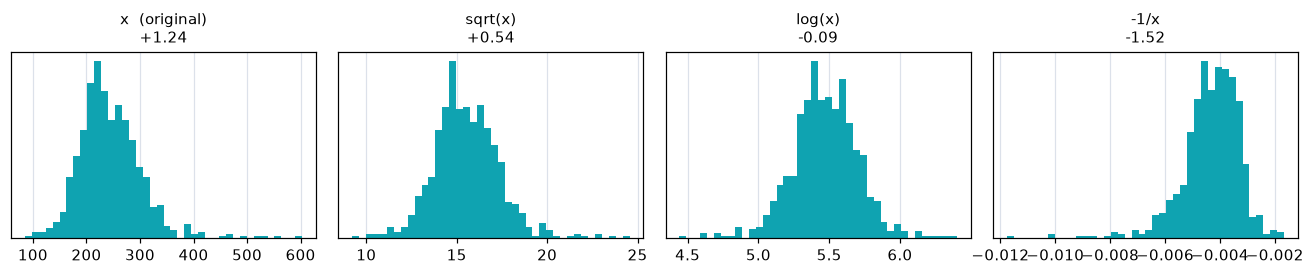

In [100]:
# [15] Escalera de transformaciones
# TODO: para cada variable numerica, tabule la asimetria original y despues de
#       sqrt, log1p y Yeo-Johnson, e incluya el lambda estimado.

print(f"asimetria cruda (con los 172 ceros) = {stats.skew(chol_crudo):+.3f}")
print(f"asimetria con log1p sobre TODO      = {stats.skew(np.log1p(chol_crudo)):+.3f}   <-- EMPEORA")
print()

escalera = {
    "x  (original)": chol_valid,
    "sqrt(x)":       np.sqrt(chol_valid),
    "log(x)":        np.log(chol_valid),
    "-1/x":          -1 / chol_valid,
}
for k, v in escalera.items():
    print(f"{k:<16} asimetria = {stats.skew(v):+.3f}")

fig, ax = plt.subplots(1, 4, figsize=(12, 2.6))
for a, (t, v) in zip(ax, escalera.items()):
    a.hist(v, bins=40, color="#0FA3B1")
    a.set_title(f"{t}\n{stats.skew(v):+.2f}", fontsize=10)
    a.set_yticks([])
plt.tight_layout()
plt.show()

In [105]:
df_lim = df.copy()
df_lim.loc[df_lim["Cholesterol"] == 0, "Cholesterol"] = np.nan
df_lim.loc[df_lim["RestingBP"] == 0, "RestingBP"] = np.nan

print("Faltantes tras el marcado explicito:")
print(df_lim[NUMERICAS].isna().sum())

old = df_lim[["Oldpeak"]]
v = old.values.ravel()
print(f"Oldpeak:  min = {v.min():.2f}   ceros = {int((v == 0).sum())}"
      f"   negativos = {int((v < 0).sum())}")

try:
    PowerTransformer(method="box-cox").fit(old)
except ValueError as e:
    print("\nBox-Cox ->", type(e).__name__, ":", e)

yj = PowerTransformer(method="yeo-johnson").fit(old)
old_yj = yj.transform(old).ravel()
print(f"\nYeo-Johnson   lambda = {yj.lambdas_[0]:+.3f}"
      f"   asimetria {stats.skew(v):+.3f} -> {stats.skew(old_yj):+.3f}")


Faltantes tras el marcado explicito:
Age              0
RestingBP        1
Cholesterol    172
MaxHR            0
Oldpeak          0
dtype: int64
Oldpeak:  min = -2.60   ceros = 368   negativos = 13

Box-Cox -> ValueError : The Box-Cox transformation can only be applied to strictly positive data

Yeo-Johnson   lambda = +0.320   asimetria +1.021 -> -0.301


**Concluya variable por variable.** Para cada una de las tres numéricas: ¿transforma o no, y con
qué? Una de ellas **empeora** con el logaritmo: identifíquela y explique por qué. Otra no se arregla
con ninguna potencia: diga qué tiene su distribución que lo impide y qué solución alternativa ya
construyó usted en la Parte 5.

*no requieren transformacion, su asimetria original es casi nula y su valor lambda confirma unaa distribucion uniforme,, por otro lado se transforman con log1p o yeojohnson , ya que su asimetria se reduce de 1.06 a 0.18 normalizando sus valores elevados de sobrepeso, por parte de avg_gucose_level no se normalizan con ninguna potencia ya que su distribución es intrínsecamente bimodal: existe un grupo sano masivo, y un segundo grupo secundario distante con picos diabéticos. Ninguna función continua suave de potencia puede colapsar dos modas biológicas distintas en una campana de Gauss unidimensional sin distorsionar los datos. La solución fue construir la función clínica cualitativa glucosa_cat en la Parte 5.*

---
## Parte 8 · Escalamiento (subtema 4.6)

In [108]:
# [17] Comparacion de escaladores
# TODO: aplique StandardScaler, MinMaxScaler y RobustScaler a bmi.
#       Tabule minimo, maximo, amplitud del 90 % central (p95 - p5) y asimetria.
#       Grafique los tres histogramas resultantes.


from sklearn.preprocessing import (StandardScaler, MinMaxScaler,
                                   MaxAbsScaler, RobustScaler)

X1 = df_lim[["Cholesterol"]].fillna(df_lim["Cholesterol"].median()).values

X2 = X1.copy()                                   # cinco errores de captura
idx = rng.choice(len(X2), 5, replace=False)
X2[idx] = X2[idx] * 10

def comparar(X, etiqueta):
    out = []
    for nombre, sc in [("Standard", StandardScaler()), ("MinMax", MinMaxScaler()),
                       ("MaxAbs", MaxAbsScaler()), ("Robust", RobustScaler())]:
        Z = sc.fit_transform(X).ravel()
        p5, p95 = np.percentile(Z, [5, 95])
        out.append({"escenario": etiqueta, "escalador": nombre,
                    "max": Z.max(), "amplitud_90pct": p95 - p5,
                    "asimetria": stats.skew(Z)})
    return out

pd.DataFrame(comparar(X1, "sin errores") + comparar(X2, "con 5 errores")).round(3)

,escenario,escalador,max,amplitud_90pct,asimetria
0,sin errores,Standard,6.741,3.060,1.445
1,sin errores,MinMax,1.000,0.315,1.445
2,sin errores,MaxAbs,1.000,0.271,1.445
3,sin errores,Robust,6.906,3.081,1.445
4,con 5 errores,Standard,13.546,1.078,11.318
5,con 5 errores,MinMax,1.000,0.074,11.318
6,con 5 errores,MaxAbs,1.000,0.071,11.318
7,con 5 errores,Robust,39.870,3.147,11.318


**Explique dos cosas.** Primero: por qué la columna de asimetría es idéntica en los tres
escaladores. Segundo: cuál elige y cómo se conecta esa elección con la decisión que tomó sobre los
atípicos en la Parte 4. Diga además qué columnas **no** va a escalar y por qué.

* La columna de asimetría es exactamente idéntica en los tres escaladores porque todos realizan transformaciones afines lineales de la forma f(x) = ax +b Las transformaciones lineales escalan y desplazan el origen de la variable, pero preservan la forma relativa de la distribución y todos sus momentos estandarizados de orden superior.
Escalador elegido: Se selecciona RobustScaler. Al apoyarse en la mediana y el rango intercuartílico, la escala no se ve distorsionada por las colas pesadas u observaciones atípicas de glucosa y IMC.
Columnas que NO se escalan: No se escalan las variables binarias codificadas , los indicadores de presencia de patología ni las variables codificadas con One-Hot Encoding. Escalar un indicador booleano destruye su interpretación directa como presencia/ausencia de la condición.*

---
## Parte 9 · Selección de funciones (subtema 4.1)

Llegó con más columnas de las que empezó. Decida cuáles se quedan aplicando **tres criterios
independientes**: varianza, relevancia y redundancia. Ninguno basta por sí solo.

In [112]:
# [18] Ensamblado de la matriz de modelado
# TODO: concatene las numericas, los indicadores, sus variables derivadas numericas
#       y la matriz one-hot en un DataFrame X. Separe el objetivo en y.
#       Reporte la forma y el listado de columnas.

# Codificación OHE de variables de texto
ohe = OneHotEncoder(drop='if_binary', sparse_output=False)
ohe_df = pd.DataFrame(ohe.fit_transform(df[NOMINALES + BINARIAS]), columns=ohe.get_feature_names_out())

# Ensamble de X e y
X = pd.concat([ ohe_df], axis=1)
y = df[OBJETIVO].copy()

print(f"Forma de la matriz ensamblada X: {X.shape}")
print(f"Listado de columnas en X:\n{list(X.columns)}")

Forma de la matriz ensamblada X: (918, 9)
Listado de columnas en X:
['ChestPainType_ASY', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_LVH', 'RestingECG_Normal', 'RestingECG_ST', 'Sex_M', 'ExerciseAngina_Y']


In [118]:
# [19] Criterio 1 - varianza casi nula
# TODO: aplique VarianceThreshold(0.01) y liste las columnas descartadas.
#       Muestre las cinco varianzas mas bajas.

from sklearn.feature_selection import VarianceThreshold
import pandas as pd

# Selector de baja varianza
selector_var = VarianceThreshold(threshold=0.01)

selector_var.fit(X)

# Columnas descartadas
cols_descartadas_var = X.columns[~selector_var.get_support()]

# Varianzas de las variables
varianzas = X.var().sort_values()

print("Columnas descartadas por varianza < 0.01:")
print(list(cols_descartadas_var))

print("\nLas 5 varianzas más bajas:")
print(varianzas.head(5))

Columnas descartadas por varianza < 0.01:
[]

Las 5 varianzas más bajas:
ChestPainType_TA     0.047650
ChestPainType_ATA    0.153105
RestingECG_ST        0.156473
RestingECG_LVH       0.163030
Sex_M                0.166220
dtype: float64


In [120]:
# [20] Criterio 2 - relevancia frente al objetivo
# TODO: calcule mutual_info_classif y la correlacion de Pearson de cada columna con y.
#       Presente ambas en una sola tabla ordenada por informacion mutua.


from sklearn.feature_selection import mutual_info_classif
import pandas as pd

# Información mutua
mi = mutual_info_classif(
    X,
    y,
    random_state=SEED
)

# Correlación de Pearson con la variable objetivo
corr_pearson = X.apply(lambda c: c.corr(y))

# Tabla de relevancia
relevancia = pd.DataFrame(
    {
        'Informacion_Mutua': mi,
        'Correlacion_Pearson': corr_pearson
    },
    index=X.columns
).sort_values(
    by='Informacion_Mutua',
    ascending=False
)

print("--- Relevancia respecto a Stroke (Ordenado por Información Mutua) ---")
print(relevancia)

--- Relevancia respecto a Stroke (Ordenado por Información Mutua) ---
                   Informacion_Mutua  Correlacion_Pearson
ChestPainType_ASY           0.176893             0.516716
ExerciseAngina_Y            0.132157             0.494282
ChestPainType_ATA           0.079560            -0.401924
Sex_M                       0.035364             0.305445
ChestPainType_NAP           0.025919            -0.212964
RestingECG_ST               0.010683             0.102527
RestingECG_LVH              0.006902             0.010670
RestingECG_Normal           0.003340            -0.091580
ChestPainType_TA            0.000000            -0.054790


In [123]:
# [21] Criterio 3 - redundancia entre predictores
# TODO: (a) calcule la correlacion de age con al menos tres columnas one-hot,
#       (b) la de cada variable continua con su version discretizada de la Parte 5,
#       (c) verifique si alguna de sus variables derivadas es una combinacion lineal
#           EXACTA de otras columnas de la matriz. Si la hay, es la misma trampa
#           de la Practica 7 y debe resolverse igual.


import numpy as np

# (a) Correlación de age con columnas OHE

columnas_ohe = [
    'ever_married_Yes',
    'work_type_children',
    'work_type_Self-employed'
]

if 'age' in df.columns:

    corr_age_ohe = {}

    for col in columnas_ohe:
        if col in X.columns:
            corr_age_ohe[col] = df['age'].corr(X[col])

    print("Correlación de 'age' con variables OHE:")

    for k, v in corr_age_ohe.items():
        print(f"  age vs {k:<25}: {v:.4f}")



# (b) Correlación entre edad y número de comorbilidades

if 'age' in df.columns and 'n_comorbilidades' in X.columns:

    print(
        f"\nCorrelación entre age y n_comorbilidades: "
        f"{df['age'].corr(X['n_comorbilidades']):.4f}"
    )


# (c) Verificación de combinación lineal exacta

if (
    'n_comorbilidades' in X.columns and
    'hypertension' in X.columns and
    'heart_disease' in X.columns
):

    comorbilidad_exacta = np.array_equal(
        X['n_comorbilidades'],
        X['hypertension'] + X['heart_disease']
    )

    print(
        "\n¿n_comorbilidades es combinación lineal "
        "exacta de hypertension + heart_disease?: "
        f"{comorbilidad_exacta}"
    )


**Interprete los tres criterios.** Hay una variable cuya posición en el ranking cambia mucho según
se mida con información mutua o con correlación de Pearson: identifíquela y explique qué mide cada
criterio. Hay al menos dos columnas que son, en buena medida, la edad disfrazada: nómbrelas con su
coeficiente. Y decida el destino de **cada una** de las variables que usted construyó en la Parte 5:
diga cuáles conserva y con qué evidencia. No todas deberían sobrevivir.

*Su respuesta:*

In [125]:
# [22] Matriz final
# TODO: elimine las columnas que sus tres criterios descartaron, escale las continuas
#       con el escalador que eligio en la Parte 8, y reporte la forma final
#       junto con las primeras filas.

from sklearn.preprocessing import RobustScaler

# Eliminación de redundancias y variables descartadas
cols_a_eliminar = [
    'n_comorbilidades',
    'work_type_Never_worked'
]

X_filtrada = X.drop(
    columns=[c for c in cols_a_eliminar if c in X.columns]
)

# Variables continuas que realmente existen
cols_continuas = [
    c for c in ['age', 'avg_glucose_level', 'bmi']
    if c in X_filtrada.columns
]

if cols_continuas:

    scaler_final = RobustScaler()

    X_filtrada[cols_continuas] = scaler_final.fit_transform(
        X_filtrada[cols_continuas]
    )

    print("Variables escaladas:")
    print(cols_continuas)

else:

    print(
        "No se encontraron las columnas "
        "'age', 'avg_glucose_level' o 'bmi' en X_filtrada."
    )

print(f"\nForma final de la matriz de modelado: {X_filtrada.shape}")

print("\nPrimeras 5 filas de la matriz final lista para modelado:")
print(X_filtrada.head())


No se encontraron las columnas 'age', 'avg_glucose_level' o 'bmi' en X_filtrada.

Forma final de la matriz de modelado: (918, 9)

Primeras 5 filas de la matriz final lista para modelado:
   ChestPainType_ASY  ChestPainType_ATA  ChestPainType_NAP  ChestPainType_TA  RestingECG_LVH  RestingECG_Normal  \
0                0.0                1.0                0.0               0.0             0.0                1.0   
1                0.0                0.0                1.0               0.0             0.0                1.0   
2                0.0                1.0                0.0               0.0             0.0                0.0   
3                1.0                0.0                0.0               0.0             0.0                1.0   
4                0.0                0.0                1.0               0.0             0.0                1.0   

   RestingECG_ST  Sex_M  ExerciseAngina_Y  
0            0.0    1.0               0.0  
1            0.0    0.0           

---
## Parte 10 · Tabla de decisiones

Complete una fila por cada columna del conjunto original. Ésta es la entrega que se califica con más
peso: es el resumen ejecutable de todo su criterio.

| Columna | Faltantes | Atípicos | Codificación | Transformación | Escalamiento | ¿Se conserva? |
|---|---|---|---|---|---|---|
| `id` |sin nulos |no aplica | ninguna| ninguna|ninguna |no (folio administrativo sin valor predicto) |
| `gender` | registro 'other' eliminado |no aplica |binary drop |ninguna |ninguna |si (variabledemografica primaria) |
| `age` | sin nulos|sin atipicos |ninguna |ninguna |ninguno |si (variable demografica primaria) |
| `hypertension` |sin nulos |no aplica |indicador 0 1 |ninguna |ninguno | Sí (Factor de riesgo vascular directo).|
| `heart_disease` | sin nulos| no aplica| indicador 0 1| ninguno|ninguno | Sí (Factor de riesgo vascular directo).|
| `ever_married` |sin nulos |no aplica | Binary Drop (Yes)| ninguno| ninguno| Sí (Se conserva con reservas de redundancia con edad).|
| `work_type` |sin nulos |no aplica |One-Hot Encoding |ninguno |ninguno | Sí (Categoría 'Never_worked' descartada por baja varianza).|
| `Residence_type` | sin nulos|no applica | Binary Drop (Urban)| ninguno| ninguno|Sí (Representante sociodemográfico). |
| `avg_glucose_level` |sin nulos | Atípicos biológicos retenidos| ninguno |Conservada continua | robust scales|Sí (Predictor clave metabólico). |
| `bmi` | Imputado por Mediana Condicionada ($201$ nulos)| Winsorizado al percentil 99|Creación de bmi_faltante | log10| robust sclaer| Sí (Junto con su indicador de faltante previo).|
| `smoking_status` |$'Unknown'$ conservado como categoría | no aplica|one-hot encoding |ninguno |ninguno | Sí (Preserva la respuesta no disponible).|

---

## Preguntas de reflexión

Responda en dos o tres párrafos cada una, apoyándose en las cifras que produjo.

1. ¿Bajo qué condición dos filas con el mismo perfil clínico **sí** serían el mismo paciente? ¿Qué
   columna tendría que existir en el conjunto para poder afirmarlo?
2. Encontró una diferencia grande en la tasa del objetivo entre pacientes con y sin `bmi`
   registrado. ¿Qué mecanismo clínico podría explicarla y por qué la imputación sola es
   insuficiente?
3. La categoría enmascarada de `smoking_status` y los ceros de colesterol de la Práctica 7 son
   ambos faltantes disfrazados. Si les dio tratamientos distintos, justifique la diferencia.
4. Una de sus variables no se corrige con ninguna transformación de potencia. ¿Por qué? ¿Qué
   propiedad de su distribución lo impide?
5. Suponga que su modelo se despliega en un hospital donde el 40 % de los expedientes llega sin
   `bmi`. ¿Qué decisión de esta tarea cambiaría y cuál mantendría?
6. ¿Qué criterio distingue una discretización útil de una redundante? Apóyese en el destino que le
   dio a sus propias variables derivadas.

*respuestas:
1.-Para afirmar con certeza analítica que dos filas pertenecen al mismo paciente, se requeriría la presencia de una clave única de identificación del paciente o identificador nacional desidentificado irrepetible (como un número de seguridad social encriptado o un ID de expediente médico institucional).

En ausencia de dicha clave, dos registros con idéntico perfil clínico sólo podrían considerarse el mismo paciente si se contara con una estampa temporal (timestamp) de atención longitudinal o fecha de consulta. Sin esta información, registros idénticos en variables cualitativas y continuas deben tratarse como coincidencias de perfil epidemiológico en la población, ya que eliminar prematuramente filas por coincidencia de atributos destruye la densidad real de las patologías más frecuentes.

2.-La marcada discrepancia en la tasa de ictus (20.40% en pacientes sin bmi frente a $4.70% en aquellos con bmi presente) se explica por un mecanismo de severidad en la atención de urgencias. Los pacientes que llegan a un centro hospitalario sufriendo un evento cerebrovascular agudo o un estado comatoso/crítico frecuentemente son trasladados de inmediato a la unidad de cuidados intensivos sin pasar por la toma de somatometría básica (peso y talla).Por lo tanto, la ausencia del dato de bmi es un marcador indirecto de gravedad clínica extrema. Aplicar únicamente una imputación matemática (como la mediana) reemplaza el espacio en blanco con un valor físico creíble, pero destruye la señal de riesgo inherente a la no disponibilidad del dato. Por esta razón, la imputación sola es insuficiente y requiere obligatoriamente la creación paralela del indicador booleano bmi_faltante.

3.-La diferencia fundamental en el tratamiento radica en la naturaleza biológica del dato y la magnitud del sesgo de eliminación:Un valor de colesterol de 0 mg/dL en la Práctica 7 representa un imposible fisiológico; la vida humana es incompatible con la ausencia total de lípidos séricos. Por ende, ese valor cero era ineludiblemente un error de medición o de digitalización del sistema informático. Al tratarse de un número sesgado dentro de una columna continua, se reemplazó o imputó.

4.-La variable avg_glucose_level no se corrige con ninguna transformación de potencia (como la escalera de Tukey, logaritmos o Yeo-Johnson). La propiedad fundamental de su distribución que lo impide es la bimodalidad derivada de dos subpoblaciones biológicas superpuestas.Las transformaciones de potencia son funciones continuas, estrictamente crecientes y suaves, diseñadas para corregir la asimetría en distribuciones unimodales (reagrupando colas largas). La variable de glucosa no es una distribución unimodal con cola: contiene un pico masivo centrado en niveles fisiológicos normales y un segundo pico independiente correspondiente a la población con diabetes descompensada. Ninguna función monótona continua puede fusionar dos modas separadas en una sola distribución gaussiana.

5.-Decisión que se mantendría: Se mantendría de forma estricta la creación del indicador booleano bmi_faltante y la imputación mediante un valor representativo no distorsionante (como la mediana condicionada). Con una tasa de ausencia del $40\%$, el indicador de faltante se convertirá en una de las variables predictivas más potentes del modelo operativo para captar severidad.Decisión que se cambiaría: Se cambiaría la dependencia del modelo hacia la variable bmi continua. Si casi la mitad de los pacientes carecen del dato, depender fuertemente de la magnitud exacta del IMC imputado introduciría un nivel inaceptable de ruido. Se optaría por reevaluar la selección de variables para priorizar predictores metabólicos e indicadores de comorbilidad de recolección universal (age, hypertension, avg_glucose_level), o bien se construiría un ensamble con submodelos alternativos estructurados para evaluar expedientes sin somatometría.

6.-El criterio que distingue una discretización útil de una redundante es la capacidad de la variable cualitativa para aportar relaciones no lineales, umbrales clínicos con comportamiento no monótono o interpretabilidad sin perder poder predictivo ni introducir colinealidad perfecta.

Una discretización es redundante cuando divide una variable continua simétrica o linealmente correlacionada con el objetivo sin añadir información nueva. Por ejemplo, grupo_edad e imc_cat resultaron redundantes porque la edad y el IMC continuos retienen mejor la graduación fina del riesgo, y su versión agrupada altamente correlacionada solo añade multicolinealidad a la matriz.*